## # Ironhack Data Analytics Bootcamp
**Author:** Erzsebet Fuzes  
**Cohort:** DAFT OCT2026  
**Topic:** Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

---

### Part 0: Import libraries, csv and preliminary examinations

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


%matplotlib inline

# Loading the Amazon UK product dataset (assuming the file name is "housing_price.csv")
df = pd.read_csv("C:/Users/fuzes/Ironhack/Learning_materials/Week_5/Day_1/lab-eda-univariate/amz_uk_price_prediction_dataset.csv")

In [26]:
import sys

# Add the package manager folder of the Anaconda base environment to the Python path,
# so that the notebook can also access the SciPy installed in Anaconda from within the .venv!
anaconda_site_packages = r"C:\Users\fuzes\anaconda3\Lib\site-packages"
if anaconda_site_packages not in sys.path:
    sys.path.insert(0, anaconda_site_packages)

# Import SciPy from Anaconda base!
from scipy.stats import chi2_contingency

In [10]:
# Display the first few rows of the dataset
print(f'Head of the dataframe:')
df.head()

Head of the dataframe:


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [11]:
# Retrieving the number of rows and columns in the dataframe
print(f'Number of rows and columns in the dataframe:\n{df.shape}')

print('\n')
print('='*60)
print('\n')

# Displaying the data types of each column in the dataframe
print(f'Data types of each column: {df.dtypes}')

Number of rows and columns in the dataframe:
(2443651, 9)




Data types of each column: uid                    int64
asin                     str
title                    str
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category                 str
dtype: object


In [12]:
# Retrieving the unique data types present in the dataframe columns
print('The unique datatypes:')
list(set(df.dtypes.tolist()))

The unique datatypes:


[dtype('int64'),
 dtype('bool'),
 dtype('float64'),
 <StringDtype(storage='python', na_value=nan)>]

In [13]:
# Extracting column names with numerical data types from the dataframe
df.select_dtypes("number").columns

Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='str')

In [14]:
# Counting and sorting the unique values for each numerical column in descending order
df.select_dtypes("number").nunique().sort_values(ascending=False)

uid                  2443651
price                  82916
reviews                19446
stars                     42
boughtInLastMonth         25
dtype: int64

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*

---


In [23]:
# 1. Crosstab betwen the product 'category' and 'isBestSeller' status
crosstab_bestseller = pd.crosstab(
    df['category'],
    df['isBestSeller'],
    margins=True,
    margins_name="Total"
).sort_values(by=True, ascending=False)

# 2. Relative proportions (percentage distribution by category)

crosstab_bestseller_pct = pd.crosstab(
    df['category'],
    df['isBestSeller'],
    normalize='index'
)*100

top_bestseller_categories = crosstab_bestseller_pct.sort_values(by=True, ascending=False)

print('--- Best-seller unit counts by category (Crosstab) ---')
display(crosstab_bestseller.head(10))
print("="*60)
print('--- Best Seller Ratios by Category (%) ---')
display(top_bestseller_categories.round(2).head(10))

--- Best-seller unit counts by category (Crosstab) ---


isBestSeller,False,True,Total
category,,,
Total,2435671,7980,2443651
Grocery,9008,556,9564
Health & Personal Care,9017,552,9569
Baby,14709,341,15050
Sports & Outdoors,835935,330,836265
Power & Hand Tools,8353,306,8659
Beauty,19010,302,19312
Pet Supplies,9152,285,9437
Arts & Crafts,9319,230,9549


--- Best Seller Ratios by Category (%) ---


isBestSeller,False,True
category,,
Grocery,94.19,5.81
Smart Home Security & Lighting,94.23,5.77
Health & Personal Care,94.23,5.77
Mobile Phone Accessories,95.75,4.25
Power & Hand Tools,96.47,3.53
"Billiard, Snooker & Pool",96.79,3.21
Pet Supplies,96.98,3.02
Home Brewing & Wine Making,97.15,2.85
Mirrors,97.20,2.80


**Are there categories where being a best-seller is more prevalent?**
Yes, there are definitely categories where "Best-Seller" status occurs significantly more frequently.
Best-Sellers:
- Grocery (5.81% of products are Best-Sellers)
- Smart Home Security & Lighting (5.77%)
- Health & Personal Care (5.77%)
- Mobile Phone Accessories (4.25%)
- Power & Hand Tools (3.53%).

Business Insights: Dominance of everyday consumer goods and accessories—in the Grocery, Health & Personal Care, and Mobile Phone Accessories categories, purchases are more heavily concentrated around top-performing "Best-Seller" products, likely due to high repeat-purchase intent and consistent demand. Significant contrast with categories showing lower rates: While the proportion of Best-Seller products across the entire platform is quite low (averaging only ~0.33%), the prevalence of Best-Sellers in the Grocery category is nearly 18 times higher than the platform-wide average.

2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

In [33]:
# Contingency table
contingecy_table = pd.crosstab(df['category'], df['isBestSeller'])

# Chi-square test
chi2_stat, p_val, dof, expected_freq = chi2_contingency(contingecy_table)

# Cramér V calculation
n = contingecy_table.sum().sum()
min_dim = min(contingecy_table.shape) - 1
cramers_v = np.sqrt(chi2_stat / (n* min_dim))

print("--- RESULTS OF STATISTICAL TESTS ---")
print(f"Chi-square statistic (Chi2 Stat): {chi2_stat:}")
print(f"p-value: {p_val:}")
print(f"Degrees of Freedom: {dof}")
print(f"Cramér's V: {cramers_v:}")

--- RESULTS OF STATISTICAL TESTS ---
Chi-square statistic (Chi2 Stat): 36540.20270061387
p-value: 0.0
Degrees of Freedom: 295
Cramér's V: 0.1222829439760564


1. Statistical significance (Chi-square test)
    – P-value (p = 0.00): Indicates that the null hypothesis is rejected.
    - **Insight**: Best-Seller status and product categories are not independent of one another. The relationship is statistically significant: Whether a product becomes a bestseller is closely linked to the category to which it belongs.
  
2. Strength of Association (Cramér's V): A value of 0.122 suggests a weak association.
Cramér's V reveals that the category itself is not a decisive factor in whether a product becomes a "Best-Seller." Other factors (e.g., price, number of reviews, star rating, promotions) play a more significant role.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

---

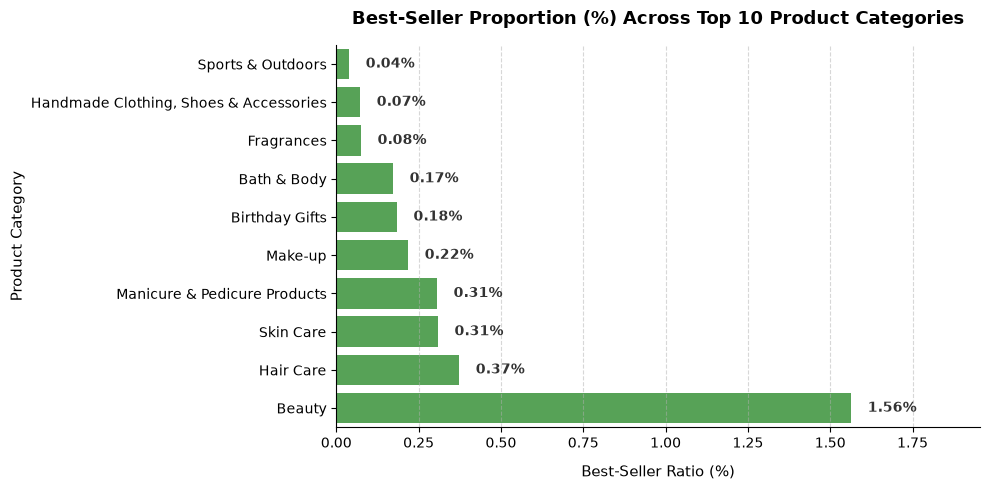

In [42]:
# 1. Filtering for the top 10 most frequent categories and crosstab (%)
top10_cat_names = df['category'].value_counts().head(10).index
crosstab_pct = pd.crosstab(df[df['category'].isin(top10_cat_names)]['category'], df['isBestSeller'], normalize='index') * 100

# 2. Conversion into a clean DataFrame, selecting the Best-Seller (True) column:
bestseller_df = crosstab_pct[True].reset_index()
bestseller_df.columns = ['category', 'bestseller_pct']

# 3. Sorting by the Best-Seller ratio
bestseller_df = bestseller_df.sort_values(by='bestseller_pct', ascending=True)

# 4. Chart
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=bestseller_df, 
    y='category', 
    x='bestseller_pct', 
    color='#2ca02c', 
    alpha=0.85
)

# Titles and axes
plt.title('Best-Seller Proportion (%) Across Top 10 Product Categories', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Best-Seller Ratio (%)', fontsize=11, labelpad=10)
plt.ylabel('Product Category', fontsize=11)
plt.xlim(0, max(bestseller_df['bestseller_pct']) * 1.25)
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Displaying percentage values at the end of the columns
for p in ax.patches:
    width = p.get_width()
    ax.text(
        width + 0.05, 
        p.get_y() + p.get_height()/2, 
        f'{width:.2f}%', 
        va='center', 
        ha='left',
        fontweight='bold', 
        fontsize=10, 
        color='#333333'
    )

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*


---


In [46]:
# 1. Calculating quartiles and the IQR (Interquartile Range) for the 'price' column
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# 2. Determining Lower and Upper Bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1 (25%): £{Q1:.2f}")
print(f"Q3 (75%): £{Q3:.2f}")
print(f"IQR: £{IQR:.2f}")
print(f"Lower Bound (GBP): {lower_bound:.2f}")
print(f"Upper Bound (GBP): {upper_bound:.2f}")
print("-" * 60)

# 3. Filter outliers
df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)].copy()

# 4. Checking results and removed rows
original_rows = len(df)
filtered_rows = len(df_no_outliers)
removed_outliers = original_rows - filtered_rows

print(f"Original number of rows: {original_rows:,}")
print(f"Number of rows kept (without outliers): {filtered_rows:,}")
print(f"Outliers removed: {removed_outliers:,} ({removed_outliers / original_rows * 100:.2f}%)")


Q1 (25%): £9.99
Q3 (75%): £45.99
IQR: £36.00
Lower Bound (GBP): -44.01
Upper Bound (GBP): 99.99
------------------------------------------------------------
Original number of rows: 2,443,651
Number of rows kept (without outliers): 2,115,963
Outliers removed: 327,688 (13.41%)



1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

---


Category with the highest median price (GBP): Desktop PCs (74.00)




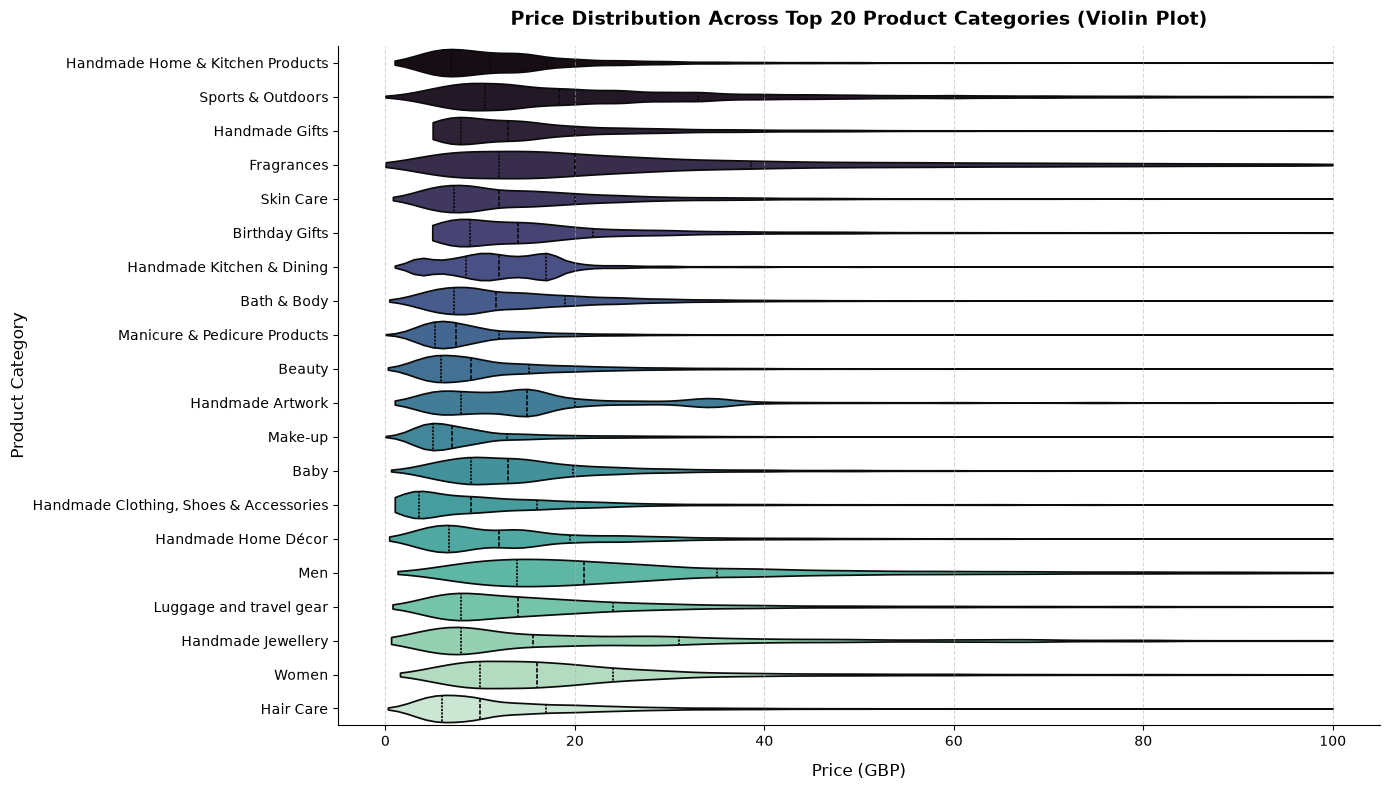

In [57]:
# -------------------------------------------------------------------------
# 1. In which category is the median price the highest? (Full dataset)
# -------------------------------------------------------------------------

category_medians = df_no_outliers.groupby('category')['price'].median()
highest_median_cat = category_medians.idxmax()
highest_median_val = category_medians.max()

print(f"Category with the highest median price (GBP): {highest_median_cat} ({highest_median_val:.2f})")
print("\n")
print("=" * 60)

# -------------------------------------------------------------------------
# 2. Violiin plot: Distribution of prices in the top 20 most frequent categories
# -------------------------------------------------------------------------
top20_categories = df_no_outliers['category'].value_counts().head(20).index
df_top20 = df_no_outliers[df_no_outliers['category'].isin(top20_categories)]

plt.figure(figsize= (14, 8))
ax = sns.violinplot(
    data=df_top20,
    y='category',
    x='price',
    hue='category',
    palette = 'mako',
    inner = 'quartile',
    cut=0
)

plt.title('Price Distribution Across Top 20 Product Categories (Violin Plot)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Price (GBP)', fontsize=12, labelpad=10)
plt.ylabel('Product Category', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

---

Category with the highest average price: Motherboards (£68.77)


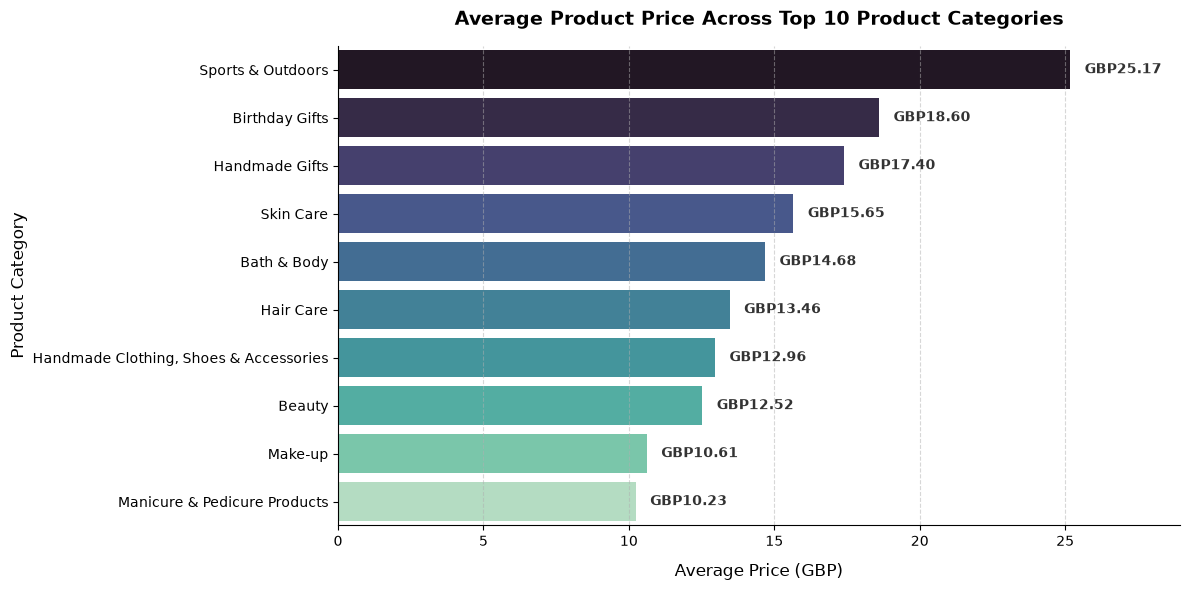

In [61]:
# -------------------------------------------------------------------------
# QUESTION 1: In which category is the average price the highest? (Full dataset)
# -------------------------------------------------------------------------
category_means = df_no_outliers.groupby('category')['price'].mean()
highest_mean_cat = category_means.idxmax()
highest_mean_val = category_means.max()

print(f"Category with the highest average price: {highest_mean_cat} (£{highest_mean_val:.2f})")
print("=" * 60)

# -------------------------------------------------------------------------
# 2. BAR CHART: Average prices in the top 10 most frequent categories
# -------------------------------------------------------------------------
# Selecting the top 10 categories based on the number of products
top10_cat_names = df_no_outliers['category'].value_counts().head(10).index
df_top10 = df_no_outliers[df_no_outliers['category'].isin(top10_cat_names)]

# Calculating average prices for the top 10 categories and sorting in descending order
top10_avg_prices = df_top10.groupby('category')['price'].mean().reset_index()
top10_avg_prices = top10_avg_prices.sort_values(by='price', ascending=False)

# Visualization
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=top10_avg_prices,
    y='category',
    x='price',
    hue='category',
    legend=False,
    palette='mako'
)

plt.title('Average Product Price Across Top 10 Product Categories', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Average Price (GBP)', fontsize=12, labelpad=10)
plt.ylabel('Product Category', fontsize=12)
plt.xlim(0, top10_avg_prices['price'].max() * 1.15)
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Print average prices at the end of the columns
for p in ax.patches: 
    width = p.get_width() 
    ax.text( 
        width + 0.5, 
        p.get_y() + p.get_height() / 2, 
        f'GBP{width:.2f}', 
        va='center', 
        ha='left', 
        fontweight='bold', 
        fontsize=10, 
        color='#333333' 
)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

---

Category with the highest median rating: Handmade Artwork (5.00 stars)




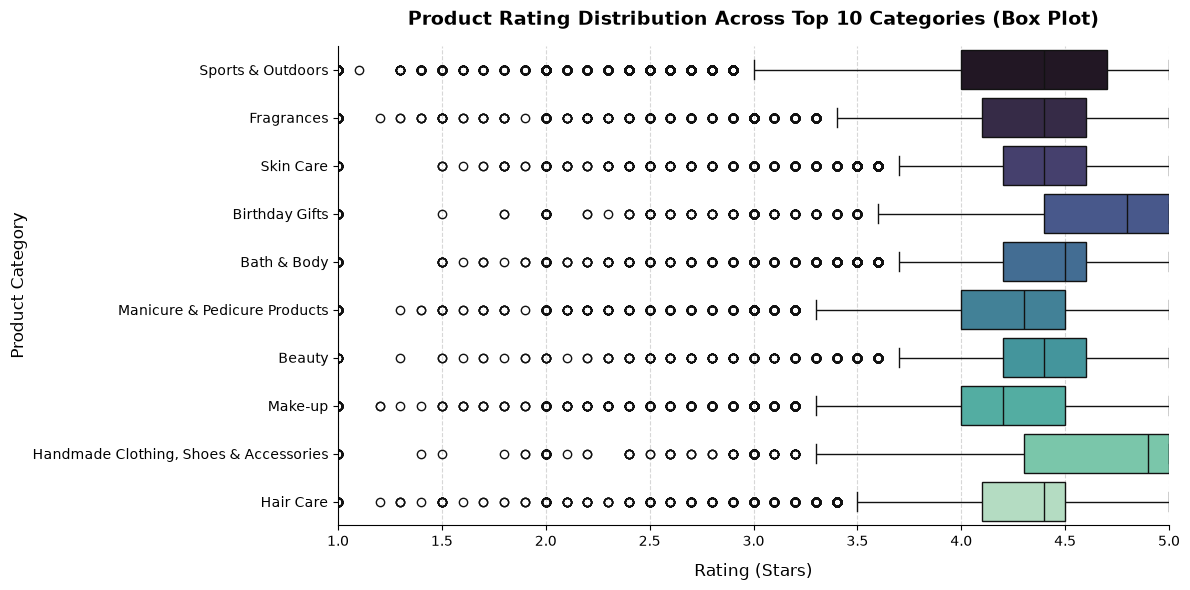

In [65]:
# -------------------------------------------------------------------------
# QUESTION 1: Which category has the highest median rating? (Full dataset)
# -------------------------------------------------------------------------
# Calculate the median rating for each category (excluding unrated products with 0 stars)
rated_df = df[df['stars'] > 0]
category_ratings_median = rated_df.groupby('category')['stars'].median()

highest_median_rating_cat = category_ratings_median.idxmax()
highest_median_rating_val = category_ratings_median.max()

print(f"Category with the highest median rating: {highest_median_rating_cat} ({highest_median_rating_val:.2f} stars)")
print("\n")
print("=" * 80)

# -------------------------------------------------------------------------
# 2. BOX PLOTS: Distribution of ratings across the top 10 most frequent categories
# -------------------------------------------------------------------------
# Selecting the top 10 categories based on the number of products
top10_categories = df['category'].value_counts().head(10).index
df_top10_ratings = rated_df[rated_df['category'].isin(top10_categories)]

# Visualization
plt.figure(figsize=(12, 6))
ax = sns.boxplot(
    data=df_top10_ratings,
    y='category',
    x='stars',
    hue='category',
    legend=False,
    palette='mako'
)

plt.title('Product Rating Distribution Across Top 10 Categories (Box Plot)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Rating (Stars)', fontsize=12, labelpad=10)
plt.ylabel('Product Category', fontsize=12)
plt.xlim(1, 5)  # Constrained to the star rating scale
plt.grid(axis='x', linestyle='--', alpha=0.5)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?


---


In [67]:
from scipy.stats import pearsonr, spearmanr

# 1. Correlation for the full dataset (without outliers)
pearson_corr_all, p_val_pearson_all = pearsonr(df_no_outliers['price'], df_no_outliers['stars'])
spearman_corr_all, p_val_spearman_all = spearmanr(df_no_outliers['price'], df_no_outliers['stars'])

# 2. Correlation for products that have actually been rated (stars > 0)
df_rated_no_outliers = df_no_outliers[df_no_outliers['stars'] > 0]
pearson_corr_rated, p_val_pearson_rated = pearsonr(df_rated_no_outliers['price'], df_rated_no_outliers['stars'])
spearman_corr_rated, p_val_spearman_rated = spearmanr(df_rated_no_outliers['price'], df_rated_no_outliers['stars'])

print("--- RESULTS OF CORRELATION TESTS (Price vs. Stars) ---")
print("1. Full dataset (without outliers):")
print(f"   - Pearson correlation:  r = {pearson_corr_all:.4f}  (p-value = {p_val_pearson_all:.4e})")
print(f"   - Spearman correlation: r = {spearman_corr_all:.4f} (p-value = {p_val_spearman_all:.4e})")
print("\n")
print("=" * 65)
print("\n")
print("2. Only products that have actually been rated (stars > 0):")
print(f" - Pearson correlation:  r = {pearson_corr_rated:.4f}  (p-value = {p_val_pearson_rated:.4e})")
print(f"   - Spearman correlation: r = {spearman_corr_rated:.4f} (p-value = {p_val_spearman_rated:.4e})")

--- RESULTS OF CORRELATION TESTS (Price vs. Stars) ---
1. Full dataset (excluding outliers):
   - Pearson correlation:  r = -0.0777  (p-value = 0.0000e+00)
   - Spearman correlation: r = -0.0668 (p-value = 0.0000e+00)




2. Only products that have actually been rated (stars > 0):
 - Pearson correlation:  r = 0.0067  (p-value = 1.0813e-12)
   - Spearman correlation: r = 0.0247 (p-value = 1.9778e-149)


	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

---


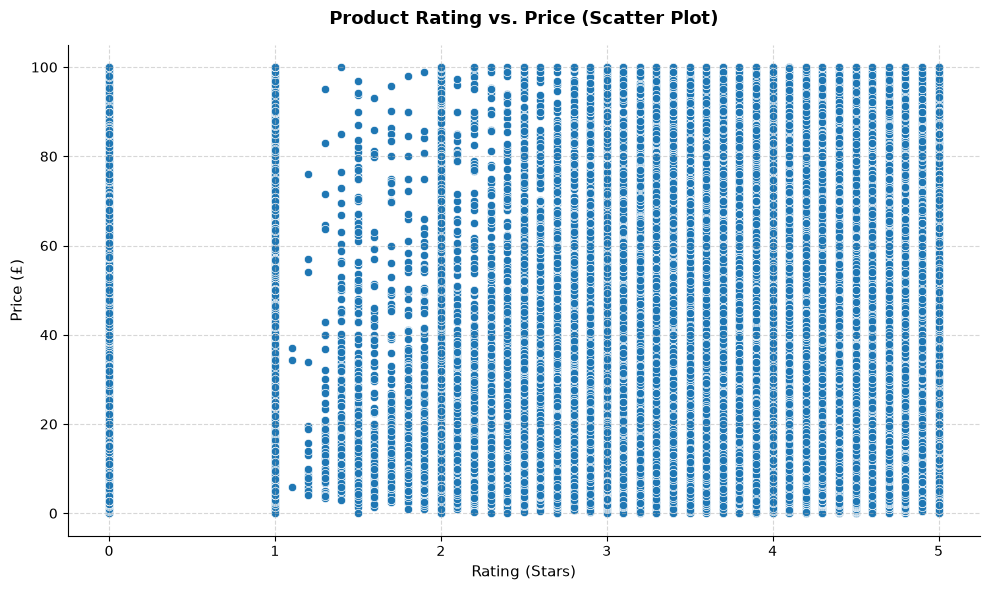

In [69]:

# Scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_no_outliers,
    x='stars',
    y='price',
    color='#1f77b4'
)

plt.title('Product Rating vs. Price (Scatter Plot)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Rating (Stars)', fontsize=11)
plt.ylabel('Price (£)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()



## Business Centric Report - Amazon UK product catalog - (Bivariate Data Analysis)

***1. Business context:***
The purpose of the analysis is to examine the price structure of products available on the Amazon UK platform, as well as the relationship between customer satisfaction and indicators of "best-seller" status (based on approximately 2.44 million data points).

***2.Key Business Findings***

**Part 1: Best-Seller Trends and Category Dependency**
-Best-Seller by Category: Across the entire dataframe, the proportion of Best-Seller products is only ~0.33% (7,980 out of 2.44 million products). In certain categories, Best-Seller status occurs much more frequently: 
    - Grocery: 5.81% (nearly 18 times the platform average)
    - Smart Home Security & Lighting: 5.77%
    - Health & Personal Care: 5.77%
    - Mobile Phone Accessories: 4.25%.

-Statistical Significance and Strength of Association: 
    - Chi-square test (chi^2): chi^2 = 36540.20, p = 0.00 (p < 0.001). The distribution of Best-Seller status is statistically significantly dependent on the product category. 
    - Cramér’s V: 0.122. The relationship is of weak. Although the category influences the odds, it does not, by itself, guarantee Best-Seller status (other factors—such as the number of reviews, price, and promotions—are also decisive). 
    
**Part 2: Price Structure and Price Variations Across Categories**
- Price-related metrics (excluding outliers):
    - Category with the highest median price (entire dataset): Desktop PCs (GBP 74.00).
    - Category with the highest average price (entire dataset): Motherboards (GBP 68.77).
    - Average prices for the top 10 most frequent categories: "Sports & Outdoors" shows the highest average price (£25.17), and "Manicure & Pedicure Products" shows the lowest (£10.23).
- Customer ratings (stars):
    - Category with the highest median rating: Handmade Artwork (5.00 stars).
    - Box plots for the top 10 most frequent categories reveal that median ratings fall within a very narrow range, between 4.3 and 4.5 stars.
    -
**Part 3: Relationship between Price and Customer Ratings**
- Lack of correlation (Price vs. Stars):
    - Entire cleaned dataset: Pearson r = -0.0777, Spearman r = -0.0668.
    - Products with ratings only (stars > 0): Pearson r = 0.0067, Spearman r = 0.0247.
    - Conclusion: There is no significant linear or monotonic relationship between price and customer ratings. More expensive products do not systematically receive better ratings from customers.
- QQ-plot and price distribution: Even after the removal of outliers, the distribution of prices does not follow a normal distribution; it remains right-skewed.

**Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?